# Lab 7: The Hubble Constant from Cepheid Distances
PHY670 Astrostatistics

Data: redshift $z$, distance modulus $\mu$ and its error $\sigma_\mu$ for 42 galaxies with Cepheid distances.

1. least-squares fit of the Hubble law and $\chi^2$ minimisation using the errors;
2. 20 synthetic realisations with a 300 km/s velocity dispersion added to the redshifts, to get the error due to peculiar motions;
3. delete-1, delete-2 and delete-3 jackknife estimates of the mean and standard deviation of $H_0$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations

c_kms = 299792.458                  # speed of light, km/s
rng = np.random.default_rng(670)    # used for the synthetic realisations (Q2)

C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"   # blue, orange, aqua
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2,
                     "axes.spines.top": False, "axes.spines.right": False})

## Data

The CSV has a header row, Windows line endings, and a stray non-breaking space (byte `0xA0`) after
most redshift values, so it is parsed by hand rather than with `np.loadtxt`.

In [2]:
DATA_FILE = "galaxies-z-distancemodulus.csv"    # columns: z, mu, sigma_mu

with open(DATA_FILE, encoding="latin-1") as f:
    lines = [ln.replace("\xa0", "").strip() for ln in f]
z, mu, sig_mu = np.array([[float(x) for x in ln.split(",")] for ln in lines[1:] if ln]).T

N = len(z)
v = c_kms * z                       # recession velocity, km/s
d = 10**((mu - 25) / 5)             # distance, Mpc
sig_d = d * np.log(10) / 5 * sig_mu # first-order error on d from sigma_mu

print(f"{N} galaxies from '{DATA_FILE}'")
print(f"z in [{z.min():.5f}, {z.max():.5f}],  cz in [{v.min():.0f}, {v.max():.0f}] km/s")
print(f"d in [{d.min():.2f}, {d.max():.2f}] Mpc,  sigma_mu in [{sig_mu.min():.3f}, {sig_mu.max():.3f}] mag")

42 galaxies from 'galaxies-z-distancemodulus.csv'
z in [0.00080, 0.01710],  cz in [241, 5126] km/s
d in [6.85, 80.43] Mpc,  sigma_mu in [0.034, 0.250] mag


**Repeated distances.** Some rows share exactly the same $\mu$ and $\sigma_\mu$. These are one Cepheid
host listed more than once, e.g. a host with two supernovae, sometimes with slightly different
redshifts. Their distance errors are therefore fully correlated, and treating them as independent
gives that host extra weight. The main analysis keeps all 42 rows, as the worksheet specifies; at
the end of Q1 we check how much merging them changes $H_0$.

In [3]:
_, grp, cnt = np.unique(np.column_stack([mu, sig_mu]), axis=0, return_inverse=True, return_counts=True)
grp = grp.ravel()
for g in np.where(cnt > 1)[0]:
    rows = np.where(grp == g)[0]
    print(f"rows {list(rows)}: mu = {mu[rows[0]]:.3f} +/- {sig_mu[rows[0]]:.3f},  z = {z[rows]}")
print(f"\n{N} rows, {len(cnt)} distinct distances")

rows [32, 33]: mu = 30.546 +/- 0.052,  z = [0.003999 0.00399 ]
rows [8, 9]: mu = 31.287 +/- 0.037,  z = [0.003896 0.003896]
rows [15, 16, 17]: mu = 33.014 +/- 0.165,  z = [0.009346 0.009346 0.009346]
rows [29, 30]: mu = 33.116 +/- 0.074,  z = [0.00948 0.0094 ]

42 rows, 37 distinct distances


## 1. Least squares and $\chi^2$

**Model.** For $z \ll 1$ the Hubble law is $v = cz = H_0 d$, with $d = 10^{(\mu-25)/5}$ Mpc. The first
correction is a factor $1 + \tfrac12(1-q_0)z$; at the largest redshift in the sample this is printed
below and is negligible next to the measurement errors.

**Ordinary least squares (no errors).** Fitting $v = H_0 d$ through the origin, minimising
$\sum_i (v_i - H_0 d_i)^2$ gives
$$\hat H_0 = \frac{\sum v_i d_i}{\sum d_i^2}, \qquad
\sigma_{H_0} = \frac{s}{\sqrt{\sum d_i^2}}, \quad s^2 = \frac{\sum (v_i - \hat H_0 d_i)^2}{N-1}.$$
For comparison we also fit $v = H_0 d + b$ with a free intercept; $b$ should be consistent with zero.

In [4]:
print(f"Next-order correction at z_max: (1-q0) z/2 = {0.5*(1+0.55)*z.max()*100:.2f}%  (q0=-0.55)")

# through the origin
H0_ols = np.sum(v*d) / np.sum(d**2)
s_ols = np.sqrt(np.sum((v - H0_ols*d)**2) / (N - 1))
sig_H0_ols = s_ols / np.sqrt(np.sum(d**2))

# with intercept: v = H0 d + b, normal equations solved by hand
Sx, Sy, Sxx, Sxy = d.sum(), v.sum(), np.sum(d**2), np.sum(d*v)
den = N*Sxx - Sx**2
H0_ols2 = (N*Sxy - Sx*Sy) / den
b_ols2 = (Sxx*Sy - Sx*Sxy) / den
s2 = np.sqrt(np.sum((v - H0_ols2*d - b_ols2)**2) / (N - 2))
sig_H0_ols2, sig_b_ols2 = s2*np.sqrt(N/den), s2*np.sqrt(Sxx/den)

print(f"OLS, v = H0 d     : H0 = {H0_ols:.2f} +/- {sig_H0_ols:.2f} km/s/Mpc   (rms scatter {s_ols:.0f} km/s)")
print(f"OLS, v = H0 d + b : H0 = {H0_ols2:.2f} +/- {sig_H0_ols2:.2f} km/s/Mpc,  b = {b_ols2:.0f} +/- {sig_b_ols2:.0f} km/s")

Next-order correction at z_max: (1-q0) z/2 = 1.33%  (q0=-0.55)
OLS, v = H0 d     : H0 = 66.97 +/- 1.73 km/s/Mpc   (rms scatter 368 km/s)
OLS, v = H0 d + b : H0 = 69.31 +/- 4.36 km/s/Mpc,  b = -84 +/- 143 km/s


**$\chi^2$ with the errors.** The quoted errors are on $\mu$, i.e. on the distance:
$\sigma_{d,i} = d_i\,\frac{\ln 10}{5}\,\sigma_{\mu,i}$. Since $d$ sits on the $x$-axis of the Hubble
diagram, we use the *effective-variance* method (Orear 1982): an error $\sigma_{d,i}$ in $x$ becomes an
error $H_0\sigma_{d,i}$ in $y = v$. Any intrinsic velocity scatter $\sigma_v$ adds in quadrature:
$$\chi^2(H_0) = \sum_i \frac{\left(v_i - H_0 d_i\right)^2}{s_i^2}, \qquad s_i^2 = \sigma_v^2 + H_0^2\sigma_{d,i}^2 .$$
In Q1 we use only the given errors, $\sigma_v = 0$; Q2 brings in $\sigma_v$. The weights $1/s_i^2$ are held
fixed while minimising and updated from the new $H_0$ until they converge. For $\sigma_v=0$ the minimum
does not depend on the weights' $H_0$:
$$\hat H_0 = \frac{\sum v_i d_i/\sigma_{d,i}^2}{\sum d_i^2/\sigma_{d,i}^2}, \qquad
\sigma_{H_0} = \Big(\sum d_i^2/s_i^2\Big)^{-1/2}.$$
We also scan $\chi^2$ on a grid in $H_0$, read off $\chi^2_{\min}$, and take the $1\sigma$ interval from
$\chi^2 \le \chi^2_{\min}+1$.

*Why not put $H_0$ inside $s_i$ while minimising?* Then $\chi^2 = \sum (v_i/H_0 - d_i)^2/\sigma_{d,i}^2$, which
treats $v$ as exact. Peculiar velocities make $v$ noisy, and that version is biased high: about
$+6$ km/s/Mpc on mock samples resembling this one (true $H_0$ known, 250 km/s peculiar velocities),
versus $<1$ for the version used here.

In [5]:
def fit_h0(v, d, sd, sig_v=0.0, n_iter=50):
    # minimum chi2 with effective variance s_i^2 = sig_v^2 + (H0 sd_i)^2; weights updated iteratively
    H = np.sum(v*d) / np.sum(d*d)
    for _ in range(n_iter):
        s = np.sqrt(sig_v**2 + (H*sd)**2)
        H = np.sum(v*d/s**2) / np.sum(d*d/s**2)
    return H, s

def chi2(H0, v, d, s):
    H0 = np.atleast_1d(H0)[:, None]
    return np.sum((v - H0*d)**2 / s**2, axis=1)

def chi2_scan(v, d, s, H0_best):
    sig = 1/np.sqrt(np.sum(d**2/s**2))
    grid = np.linspace(H0_best - 10*sig, H0_best + 10*sig, 8001)
    c2 = chi2(grid, v, d, s)
    inside = grid[c2 <= c2.min() + 1]
    return grid, c2, grid[np.argmin(c2)], c2.min(), inside.min(), inside.max()

H0_hat, s_hat = fit_h0(v, d, sig_d)
H0_grid, chi2_grid, H0_grid_min, chi2_min, lo, hi = chi2_scan(v, d, s_hat, H0_hat)
sig_H0_stat = 0.5*(hi - lo)
dof = N - 1

print(f"closed form : H0 = {H0_hat:.2f} +/- {1/np.sqrt(np.sum(d**2/s_hat**2)):.2f} km/s/Mpc")
print(f"grid minimum: H0 = {H0_grid_min:.2f}  (+{hi-H0_grid_min:.2f} / -{H0_grid_min-lo:.2f}) km/s/Mpc")
print(f"chi2_min = {chi2_min:.1f} for {dof} dof  ->  reduced chi2 = {chi2_min/dof:.2f}")

closed form : H0 = 65.33 +/- 0.32 km/s/Mpc
grid minimum: H0 = 65.33  (+0.32 / -0.32) km/s/Mpc
chi2_min = 4054.3 for 41 dof  ->  reduced chi2 = 98.89


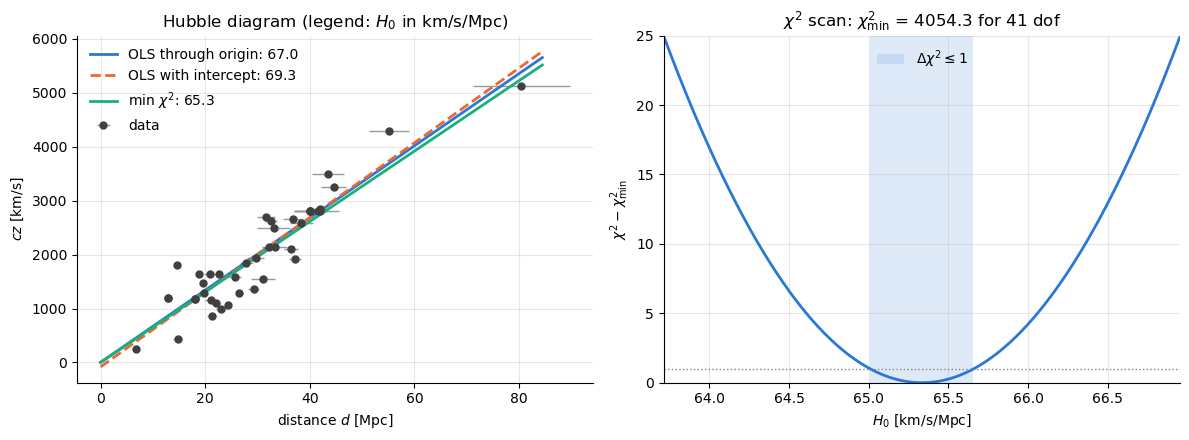

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

dd = np.linspace(0, d.max()*1.05, 200)
ax[0].errorbar(d, v, xerr=sig_d, fmt="o", ms=5, color="0.25", ecolor="0.6", elinewidth=1, label="data")
ax[0].plot(dd, H0_ols*dd, color=C1, label=f"OLS through origin: {H0_ols:.1f}")
ax[0].plot(dd, H0_ols2*dd + b_ols2, color=C2, ls="--", label=f"OLS with intercept: {H0_ols2:.1f}")
ax[0].plot(dd, H0_hat*dd, color=C3, label=fr"min $\chi^2$: {H0_hat:.1f}")
ax[0].set_xlabel("distance $d$ [Mpc]"); ax[0].set_ylabel("$cz$ [km/s]")
ax[0].set_title("Hubble diagram (legend: $H_0$ in km/s/Mpc)")
ax[0].legend(frameon=False)

ax[1].plot(H0_grid, chi2_grid - chi2_min, color=C1)
ax[1].axhline(1, color="0.5", lw=1, ls=":")
ax[1].axvspan(lo, hi, color=C1, alpha=0.15, lw=0, label=r"$\Delta\chi^2 \leq 1$")
ax[1].set_xlim(H0_grid_min - 5*sig_H0_stat, H0_grid_min + 5*sig_H0_stat)
ax[1].set_ylim(0, 25)
ax[1].set_xlabel("$H_0$ [km/s/Mpc]"); ax[1].set_ylabel(r"$\chi^2 - \chi^2_{\min}$")
ax[1].set_title(fr"$\chi^2$ scan: $\chi^2_{{\min}}$ = {chi2_min:.1f} for {dof} dof")
ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

**$\chi^2$ in magnitude space.** The errors are quoted on $\mu$, so the most direct $\chi^2$ compares
the distance moduli themselves with the model $\mu^{\rm model}_i = 5\log_{10}(cz_i/H_0) + 25$:
$$\chi^2_\mu(H_0) = \sum_i \frac{\left(\mu_i - 5\log_{10}(cz_i/H_0) - 25\right)^2}{\sigma_{\mu,i}^2}.$$
The model is linear in $A = 5\log_{10}H_0$, so the minimum is a weighted mean,
$\hat A = \sum w_i\,(5\log_{10}cz_i + 25 - \mu_i)/\sum w_i$ with $w_i = 1/\sigma_{\mu,i}^2$, and
$\sigma_{H_0} = H_0\frac{\ln 10}{5}\big(\sum w_i\big)^{-1/2}$. As before we also scan $\chi^2_\mu$ on a grid.
This version needs $z_i > 0$ for every galaxy, which holds for this data set.

It weights galaxies differently from the velocity-space fit: each galaxy counts by its *fractional*
distance error, and a peculiar velocity shifts $\log cz$ most for the nearest galaxies. So the two
estimates need not agree within their formal errors. With $\chi^2_\nu \gg 1$ in both, those formal
errors are not the real uncertainty anyway (see Q2 and Q3).

closed form : H0 = 62.24 +/- 0.31 km/s/Mpc
grid minimum: H0 = 62.24  (+0.31 / -0.31) km/s/Mpc
chi2_min = 3952.7 for 41 dof  ->  reduced chi2 = 96.41
(velocity-space chi2 above: H0 = 65.33 +/- 0.32)


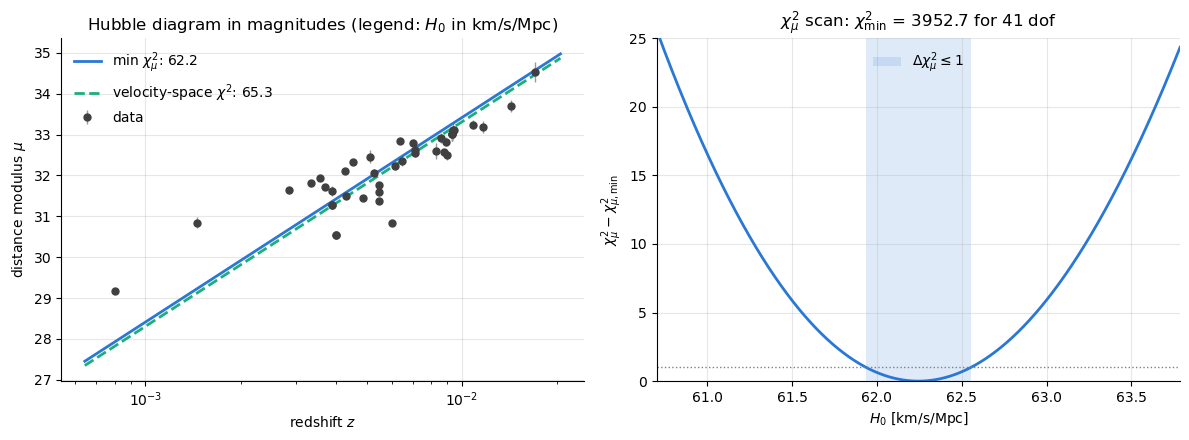

In [7]:
assert np.all(z > 0), "magnitude-space fit needs z > 0"

def chi2_mu(H0, z, mu, sig_mu):
    H0 = np.atleast_1d(H0)[:, None]
    return np.sum((mu - 5*np.log10(c_kms*z/H0) - 25)**2 / sig_mu**2, axis=1)

w_mu = 1 / sig_mu**2
A_hat = np.sum(w_mu*(5*np.log10(c_kms*z) + 25 - mu)) / np.sum(w_mu)    # A = 5 log10 H0
H0_mu = 10**(A_hat/5)
sig_H0_mu_an = H0_mu*np.log(10)/5 / np.sqrt(np.sum(w_mu))

grid_mu = np.linspace(H0_mu - 10*sig_H0_mu_an, H0_mu + 10*sig_H0_mu_an, 8001)
c2_mu = chi2_mu(grid_mu, z, mu, sig_mu)
chi2min_mu, H0_mu_grid = c2_mu.min(), grid_mu[np.argmin(c2_mu)]
ins = grid_mu[c2_mu <= chi2min_mu + 1]
lo_mu, hi_mu = ins.min(), ins.max()
sig_H0_mu = 0.5*(hi_mu - lo_mu)

print(f"closed form : H0 = {H0_mu:.2f} +/- {sig_H0_mu_an:.2f} km/s/Mpc")
print(f"grid minimum: H0 = {H0_mu_grid:.2f}  (+{hi_mu-H0_mu_grid:.2f} / -{H0_mu_grid-lo_mu:.2f}) km/s/Mpc")
print(f"chi2_min = {chi2min_mu:.1f} for {dof} dof  ->  reduced chi2 = {chi2min_mu/dof:.2f}")
print(f"(velocity-space chi2 above: H0 = {H0_hat:.2f} +/- {sig_H0_stat:.2f})")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
zz = np.geomspace(z.min()*0.8, z.max()*1.2, 200)
ax[0].errorbar(z, mu, yerr=sig_mu, fmt="o", ms=5, color="0.25", ecolor="0.6", elinewidth=1, label="data")
ax[0].plot(zz, 5*np.log10(c_kms*zz/H0_mu) + 25, color=C1, label=fr"min $\chi^2_\mu$: {H0_mu:.1f}")
ax[0].plot(zz, 5*np.log10(c_kms*zz/H0_hat) + 25, color=C3, ls="--", label=fr"velocity-space $\chi^2$: {H0_hat:.1f}")
ax[0].set_xscale("log")
ax[0].set_xlabel("redshift $z$"); ax[0].set_ylabel(r"distance modulus $\mu$")
ax[0].set_title("Hubble diagram in magnitudes (legend: $H_0$ in km/s/Mpc)")
ax[0].legend(frameon=False)

ax[1].plot(grid_mu, c2_mu - chi2min_mu, color=C1)
ax[1].axhline(1, color="0.5", lw=1, ls=":")
ax[1].axvspan(lo_mu, hi_mu, color=C1, alpha=0.15, lw=0, label=r"$\Delta\chi^2_\mu \leq 1$")
ax[1].set_xlim(H0_mu_grid - 5*sig_H0_mu, H0_mu_grid + 5*sig_H0_mu)
ax[1].set_ylim(0, 25)
ax[1].set_xlabel("$H_0$ [km/s/Mpc]"); ax[1].set_ylabel(r"$\chi^2_\mu - \chi^2_{\mu,\min}$")
ax[1].set_title(fr"$\chi^2_\mu$ scan: $\chi^2_{{\min}}$ = {chi2min_mu:.1f} for {dof} dof")
ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

**Reading the result.** The reduced $\chi^2$ shows whether the distance errors alone explain the
scatter about the Hubble line. If it is well above 1, they do not: the extra scatter comes from
peculiar velocities, which are not in $\sigma_\mu$, and the $\Delta\chi^2=1$ error underestimates the true
uncertainty. The weights $1/\sigma_{d,i}^2 \propto 1/d_i^2$ also favour the nearest galaxies, which are
exactly the ones whose velocities peculiar motions disturb most. Q2 quantifies this.

**Check: merging repeated hosts.** Each group of rows with the same distance becomes one point, with
the mean redshift.

In [8]:
v_u, d_u, sd_u = (np.bincount(grp, weights=x) / cnt for x in (v, d, sig_d))
H0_ols_u = np.sum(v_u*d_u) / np.sum(d_u**2)
H0_hat_u, s_u = fit_h0(v_u, d_u, sd_u)
print(f"{len(cnt)} merged points: OLS H0 = {H0_ols_u:.2f},  min chi2 H0 = {H0_hat_u:.2f} +/- "
      f"{1/np.sqrt(np.sum(d_u**2/s_u**2)):.2f} km/s/Mpc,  reduced chi2 = {chi2(H0_hat_u, v_u, d_u, s_u)[0]/(len(cnt)-1):.2f}")
print(f"(all {N} rows: OLS H0 = {H0_ols:.2f},  min chi2 H0 = {H0_hat:.2f} km/s/Mpc)")

37 merged points: OLS H0 = 66.62,  min chi2 H0 = 63.89 +/- 0.35 km/s/Mpc,  reduced chi2 = 108.01
(all 42 rows: OLS H0 = 66.97,  min chi2 H0 = 65.33 km/s/Mpc)


## 2. Peculiar velocities: synthetic realisations

Each galaxy's observed redshift contains a peculiar velocity $v_{\rm pec}$ on top of the Hubble flow.
To see how much this moves $H_0$, we make synthetic data sets
$$z_i^{\rm syn} = z_i + \frac{\delta v_i}{c}, \qquad \delta v_i \sim \mathcal N(0,\, 300~{\rm km/s}),$$
keeping $\mu_i$ and $\sigma_{\mu,i}$ fixed, and refit each one with the same $\chi^2$ estimator as in Q1.
The spread of the 20 fitted values is the error due to peculiar motions.

In [9]:
N_REAL, SIG_V = 20, 300.0

H0_syn = np.empty(N_REAL)
for k in range(N_REAL):
    z_syn = z + SIG_V/c_kms * rng.standard_normal(N)
    H0_syn[k] = fit_h0(c_kms*z_syn, d, sig_d)[0]

sig_H0_pec = H0_syn.std(ddof=1)
print("H0 for the 20 realisations [km/s/Mpc]:")
print(np.array2string(H0_syn, precision=2, max_line_width=100))
print(f"\nmean = {H0_syn.mean():.2f},  std (peculiar-velocity error) = {sig_H0_pec:.2f} km/s/Mpc")
print(f"(a std from 20 samples is itself uncertain by ~1/sqrt(2*19) = {100/np.sqrt(38):.0f}%)")

# check with many more realisations
big = np.array([fit_h0(v + SIG_V*rng.standard_normal(N), d, sig_d)[0] for _ in range(20000)])
print(f"check, 20000 realisations: mean = {big.mean():.2f}, std = {big.std(ddof=1):.2f} km/s/Mpc")

sig_H0_tot = np.hypot(sig_H0_stat, sig_H0_pec)
print(f"\nH0 = {H0_hat:.2f} +/- {sig_H0_stat:.2f} (distance errors) +/- {sig_H0_pec:.2f} (peculiar velocities)"
      f"  =  {H0_hat:.2f} +/- {sig_H0_tot:.2f} km/s/Mpc")

H0 for the 20 realisations [km/s/Mpc]:
[66.21 73.37 68.34 75.24 62.85 62.07 63.61 64.52 57.65 66.45 66.81 63.06 70.3  57.72 56.27 61.13
 73.58 70.74 65.77 57.31]

mean = 65.15,  std (peculiar-velocity error) = 5.64 km/s/Mpc
(a std from 20 samples is itself uncertain by ~1/sqrt(2*19) = 16%)
check, 20000 realisations: mean = 65.35, std = 4.37 km/s/Mpc

H0 = 65.33 +/- 0.32 (distance errors) +/- 5.64 (peculiar velocities)  =  65.33 +/- 5.65 km/s/Mpc


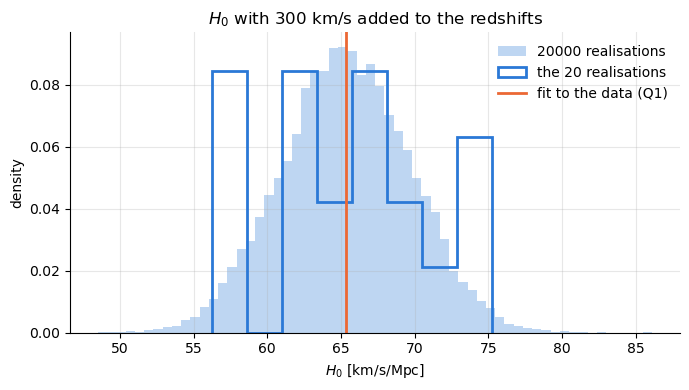

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(big, bins=60, density=True, color=C1, alpha=0.3, label="20000 realisations")
ax.hist(H0_syn, bins=8, density=True, histtype="step", color=C1, lw=2, label="the 20 realisations")
ax.axvline(H0_hat, color=C2, label="fit to the data (Q1)")
ax.set_xlabel("$H_0$ [km/s/Mpc]"); ax.set_ylabel("density")
ax.set_title("$H_0$ with 300 km/s added to the redshifts")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

**Peculiar velocities in the error budget.** We can also put the velocity dispersion directly into
$\chi^2$ through the $\sigma_v$ term of the effective variance, $s_i^2 = \sigma_v^2 + H_0^2\sigma_{d,i}^2$.
This changes the weighting: the nearest galaxies, whose distance errors are small in km/s but whose
velocities are dominated by peculiar motion, no longer dominate the fit. If 300 km/s describes the
peculiar motions well, the reduced $\chi^2$ should come out close to 1.

In [11]:
H0_pv, s_pv = fit_h0(v, d, sig_d, sig_v=SIG_V)
_, c2_pv, _, c2min_pv, lo_pv, hi_pv = chi2_scan(v, d, s_pv, H0_pv)
print(f"with sigma_v = {SIG_V:.0f} km/s in the errors: H0 = {H0_pv:.2f} "
      f"(+{hi_pv-H0_pv:.2f} / -{H0_pv-lo_pv:.2f}) km/s/Mpc,  reduced chi2 = {c2min_pv/dof:.2f}")

with sigma_v = 300 km/s in the errors: H0 = 66.65 (+1.65 / -1.65) km/s/Mpc,  reduced chi2 = 1.34


## 3. Jackknife resampling

The **delete-$k$ jackknife** removes every possible set of $k$ galaxies, refits $H_0$ (the Q1 $\chi^2$
estimator) on the remaining $N-k$, and uses the spread of the $\binom{N}{k}$ subset values
$\hat H_{0,S}$. With $\bar H_0$ their mean,
$$\sigma^2_{\rm jack} = \frac{N-k}{k\binom{N}{k}} \sum_S \left(\hat H_{0,S} - \bar H_0\right)^2,
\qquad
\widehat{\rm bias} = \frac{N-k}{k}\left(\bar H_0 - \hat H_0\right),$$
and the bias-corrected estimate is $\hat H_0 - \widehat{\rm bias}$. (For $k=1$ these reduce to the usual
$\frac{N-1}{N}\sum$ and $(N-1)(\bar H_0 - \hat H_0)$.) The prefactor is needed because the subsets
overlap almost completely, so the raw spread of $\hat H_{0,S}$ is far smaller than the real error.

For $N=42$ there are 42, 861 and 11480 subsets for $k=1,2,3$. Since $\hat H_0$ only depends on two
sums, each subset fit is the full sum minus the dropped terms, so all subsets are done at once.

In [12]:
def jackknife(v, d, sd, k):
    w = 1 / sd**2
    a, b = w*v*d, w*d*d                       # H0 = sum(a) / sum(b)
    drop = np.array(list(combinations(range(len(v)), k)))
    H = (a.sum() - a[drop].sum(axis=1)) / (b.sum() - b[drop].sum(axis=1))
    n, M = len(v), len(H)
    mean = H.mean()
    sig = np.sqrt((n - k) / (k * M) * np.sum((H - mean)**2))
    bias = (n - k) / k * (mean - a.sum()/b.sum())
    return H, mean, sig, bias

jk = {}
print(f"full-sample H0 = {H0_hat:.3f} km/s/Mpc\n")
print(f"{'k':>2} {'subsets':>8} {'mean':>9} {'sigma_jack':>11} {'bias':>8} {'corrected':>10} {'raw std':>8}")
for k in (1, 2, 3):
    H, mean, sig, bias = jackknife(v, d, sig_d, k)
    jk[k] = (H, mean, sig)
    print(f"{k:>2} {len(H):>8} {mean:>9.3f} {sig:>11.3f} {bias:>8.3f} {H0_hat-bias:>10.3f} {H.std():>8.3f}")
print(f"\nfor comparison: Delta chi2 = 1 error = {sig_H0_stat:.3f},  "
      f"combined with peculiar velocities (Q2) = {sig_H0_tot:.3f}")

full-sample H0 = 65.333 km/s/Mpc

 k  subsets      mean  sigma_jack     bias  corrected  raw std
 1       42    65.338       4.872    0.178     65.155    0.761
 2      861    65.342       4.872    0.178     65.155    1.089
 3    11480    65.347       4.872    0.178     65.156    1.351

for comparison: Delta chi2 = 1 error = 0.324,  combined with peculiar velocities (Q2) = 5.648


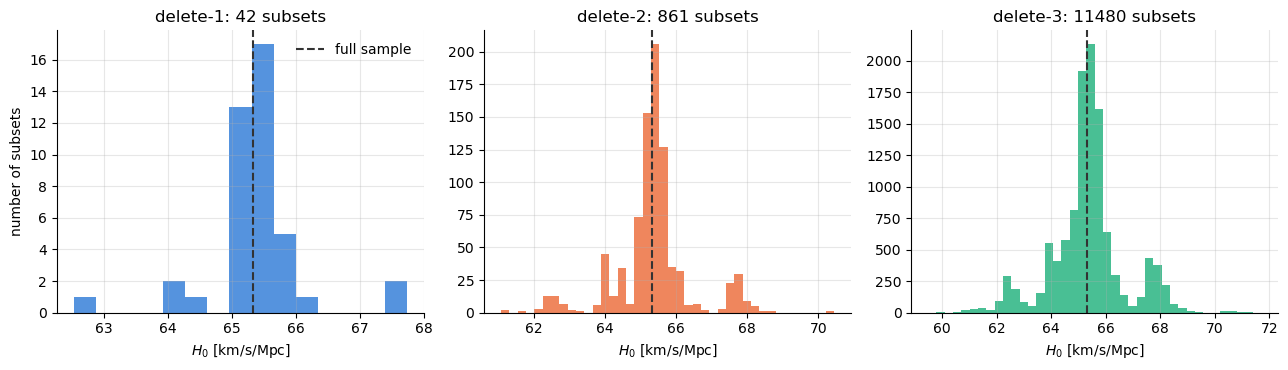

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a_, k, col in zip(ax, (1, 2, 3), (C1, C2, C3)):
    a_.hist(jk[k][0], bins=40 if k > 1 else 15, color=col, alpha=0.8)
    a_.axvline(H0_hat, color="0.2", lw=1.5, ls="--", label="full sample")
    a_.set_title(f"delete-{k}: {len(jk[k][0])} subsets")
    a_.set_xlabel("$H_0$ [km/s/Mpc]")
ax[0].set_ylabel("number of subsets"); ax[0].legend(frameon=False)
plt.tight_layout(); plt.show()

**Reading the jackknife.** The delete-1, -2 and -3 estimates of $\sigma$ should agree with each other;
if they do, no single galaxy or pair drives the result. Unlike the $\Delta\chi^2=1$ error, the jackknife
uses the actual scatter of the data, so it also picks up the peculiar-velocity scatter. It should
therefore be closer to the combined error from Q2 than to the distance-only error. In the histograms,
isolated subsets far from the main peak show which galaxies pull the fit most.

In [14]:
print("Summary  (H0 in km/s/Mpc)")
print(f"  OLS through origin           : {H0_ols:7.2f} +/- {sig_H0_ols:.2f}")
print(f"  OLS with intercept           : {H0_ols2:7.2f} +/- {sig_H0_ols2:.2f}")
print(f"  min chi2 (distance errors)   : {H0_hat:7.2f} +/- {sig_H0_stat:.2f}   chi2_min/dof = {chi2_min/dof:.2f}")
print(f"  min chi2 in mu space         : {H0_mu:7.2f} +/- {sig_H0_mu:.2f}   chi2_min/dof = {chi2min_mu/dof:.2f}")
print(f"  + peculiar velocities (Q2)   : {H0_hat:7.2f} +/- {sig_H0_tot:.2f}   (pec. part {sig_H0_pec:.2f})")
print(f"  min chi2 with sigma_v = 300  : {H0_pv:7.2f} +/- {0.5*(hi_pv-lo_pv):.2f}   chi2_min/dof = {c2min_pv/dof:.2f}")
for k in (1, 2, 3):
    print(f"  jackknife delete-{k}           : {jk[k][1]:7.2f} +/- {jk[k][2]:.2f}")

Summary  (H0 in km/s/Mpc)
  OLS through origin           :   66.97 +/- 1.73
  OLS with intercept           :   69.31 +/- 4.36
  min chi2 (distance errors)   :   65.33 +/- 0.32   chi2_min/dof = 98.89
  min chi2 in mu space         :   62.24 +/- 0.31   chi2_min/dof = 96.41
  + peculiar velocities (Q2)   :   65.33 +/- 5.65   (pec. part 5.64)
  min chi2 with sigma_v = 300  :   66.65 +/- 1.65   chi2_min/dof = 1.34
  jackknife delete-1           :   65.34 +/- 4.87
  jackknife delete-2           :   65.34 +/- 4.87
  jackknife delete-3           :   65.35 +/- 4.87


## Summary of results

All values of $H_0$ are in km/s/Mpc, from the 42 galaxies in `galaxies-z-distancemodulus.csv`.

| Method | $H_0$ | Notes |
|---|---|---|
| **Q1** OLS, $v = H_0 d$ | $66.97 \pm 1.73$ | rms scatter about the line 368 km/s |
| **Q1** OLS, $v = H_0 d + b$ | $69.31 \pm 4.36$ | $b = -84 \pm 143$ km/s, consistent with 0 |
| **Q1** min $\chi^2$, velocity space (effective variance) | $65.33 \pm 0.32$ | $\chi^2_{\min} = 4054$ for 41 dof ($\chi^2_\nu = 98.9$) |
| **Q1** min $\chi^2_\mu$, magnitude space | $62.24 \pm 0.31$ | $\chi^2_{\min} = 3953$ for 41 dof ($\chi^2_\nu = 96.4$) |
| Q1 check: repeated hosts merged (37 points) | $63.89 \pm 0.35$ | OLS gives 66.62 |
| **Q2** 20 realisations, $+300$ km/s dispersion | mean $65.15$, std $5.64$ | 20000 realisations: std 4.37 |
| **Q1 + Q2** combined | $\mathbf{65.3 \pm 5.7}$ | $0.32$ (distances) $\oplus$ $5.64$ (peculiar velocities) |
| min $\chi^2$ with $\sigma_v = 300$ km/s in the errors | $66.65 \pm 1.65$ | $\chi^2_\nu = 1.34$ |
| **Q3** jackknife, delete-1 (42 subsets) | $65.34 \pm 4.87$ | bias-corrected 65.16 |
| **Q3** jackknife, delete-2 (861 subsets) | $65.34 \pm 4.87$ | bias-corrected 65.16 |
| **Q3** jackknife, delete-3 (11480 subsets) | $65.35 \pm 4.87$ | bias-corrected 65.16 |

**Conclusions**

1. **Least squares and $\chi^2$ (Q1).** All the fits give $H_0 \approx 65$–$69$ km/s/Mpc. The intercept is
   consistent with zero, as the Hubble law requires. The two $\chi^2$ versions (velocity space: 65.3;
   magnitude space, directly on the quoted $\sigma_\mu$: 62.2) differ by about 3 km/s/Mpc. They weight
   the nearby, peculiar-velocity-dominated galaxies differently, and the difference is well inside the
   real uncertainty found in Q2 and Q3. The quoted distance errors alone cannot explain
   the scatter: $\chi^2_\nu \approx 99$. So the formal $\Delta\chi^2 = 1$ error of $\pm 0.32$ is far too small.
2. **Peculiar velocities (Q2).** A 300 km/s velocity dispersion moves $H_0$ by $\approx 5.6$ km/s/Mpc
   (4.4 with 20000 realisations; a spread estimated from only 20 realisations is itself uncertain by
   $\sim$16%). This is the dominant error for galaxies this nearby ($cz \lesssim 5000$ km/s), giving
   $H_0 = 65.3 \pm 5.7$ km/s/Mpc. Putting $\sigma_v = 300$ km/s into the $\chi^2$ brings $\chi^2_\nu$ down to
   1.34: peculiar motions of this size account for most of the extra scatter.
3. **Jackknife (Q3).** The delete-1, -2 and -3 jackknives give the same result, $65.3 \pm 4.9$ km/s/Mpc.
   The bias is small ($0.18$). The jackknife error uses the actual scatter of the data, and it agrees
   with the peculiar-velocity error from Q2 rather than with the formal $\chi^2$ error. This confirms
   that peculiar motions, not the distance errors, set the uncertainty on $H_0$.
4. **Data caveat.** The 42 rows contain only 37 distinct Cepheid distances; some hosts appear more
   than once. Merging them lowers the $\chi^2$ estimate by $1.4$ km/s/Mpc, well within the
   $\sim 5$ km/s/Mpc uncertainty.